In [3]:
from tensorflow.keras.datasets import mnist
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

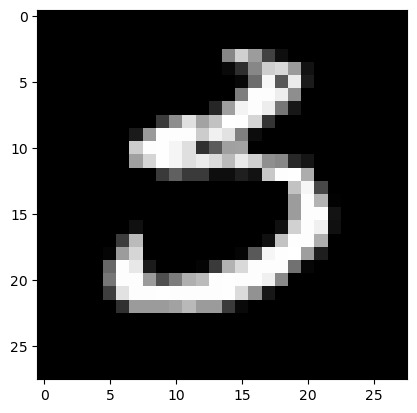

y = 3


In [13]:
import matplotlib.pyplot as plt
%matplotlib inline

id = 6920
imagen = train_images[id]

fig = plt.figure
plt.imshow(imagen, cmap='gray')
plt.show()

print(f"y = {train_labels[id]}")

In [15]:
train_images.shape

(60000, 28, 28)

In [49]:
# Crear la red Neuronal
from tensorflow import keras
from tensorflow.keras import layers

modelo_RN = keras.Sequential([
    layers.Dense(784, activation="relu"),
    layers.Dense(392, activation="relu"),
    layers.Dense(10, activation="sigmoid")
])

In [51]:
modelo_RN.compile(
    optimizer = "rmsprop",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [53]:
#Preprocesamiento
X_train = train_images.reshape((60000, 28*28))
X_train = X_train.astype("float32")/255

X_test = test_images.reshape((10000, 28*28))
X_test = X_test.astype("float32")/255

print(X_train.shape)
print(X_test.shape)

(60000, 784)
(10000, 784)


In [55]:
historial = modelo_RN.fit(X_train, train_labels, epochs=10, batch_size=100, validation_data=(X_test, test_labels))

Epoch 1/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8861 - loss: 0.3756 - val_accuracy: 0.9675 - val_loss: 0.1001
Epoch 2/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9739 - loss: 0.0842 - val_accuracy: 0.9765 - val_loss: 0.0720
Epoch 3/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9838 - loss: 0.0499 - val_accuracy: 0.9772 - val_loss: 0.0742
Epoch 4/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9897 - loss: 0.0330 - val_accuracy: 0.9822 - val_loss: 0.0676
Epoch 5/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9930 - loss: 0.0222 - val_accuracy: 0.9791 - val_loss: 0.0706
Epoch 6/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9943 - loss: 0.0178 - val_accuracy: 0.9828 - val_loss: 0.0688
Epoch 7/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.9963 - loss: 0.0117 - val_accuracy: 0.9792 - val_loss: 0.0870
Epoch 8/10
600/600 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9966 - loss: 0.0099 - val_accuracy: 0.

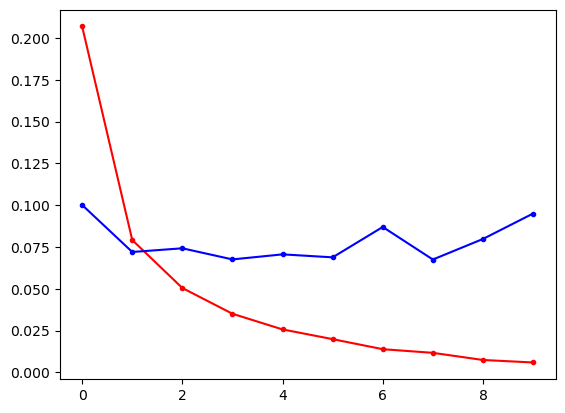

In [58]:
# Graficar la pérdida de la evolución del entrenamiento
plt.plot(historial.history["loss"], 'r', marker='.', label = 'Train Loss')
plt.plot(historial.history["val_loss"], 'b', marker='.', label = 'Validation Loss')
plt.show();

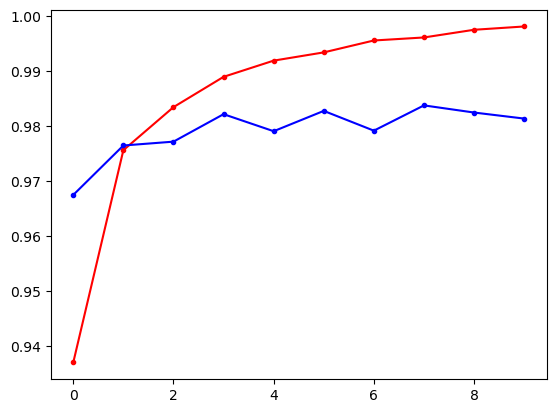

In [60]:
# Graficar la pérdida de la evolución del entrenamiento
plt.plot(historial.history["accuracy"], 'r', marker='.', label = 'Train Loss')
plt.plot(historial.history["val_accuracy"], 'b', marker='.', label = 'Validation Loss')
plt.show();

In [62]:
modelo_RN.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (100, 784)             │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (100, 392)             │       307,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (100, 10)              │         3,930 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,854,182 (7.07 MB)

 Trainable params: 927,090 (3.54 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 927,092 (3.54 MB)

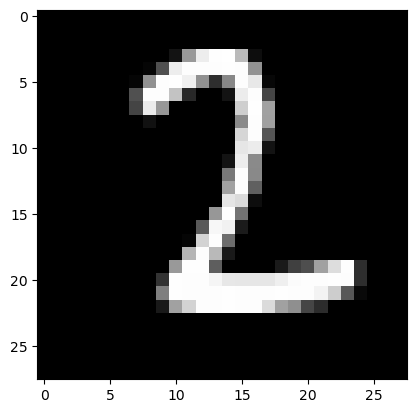

y = 2


In [72]:
# Ejemplo de Predicción

id = 6920
imagen = test_images[id]

fig = plt.figure
plt.imshow(imagen, cmap='gray')
plt.show()

print(f"y = {test_labels[id]}")

In [66]:
# Evaluación del conjunto de testeo

y_pred = modelo_RN.predict(X_test)
print(f"y_pred= {y_pred}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 883us/step
y_pred= [[7.30019378e-09 7.52322933e-08 1.93653094e-07 ... 9.99997735e-01
  5.54076285e-10 9.90466867e-03]
 [1.37167366e-09 9.31802606e-06 9.99980032e-01 ... 2.15920320e-11
  5.31023190e-08 3.38997868e-18]
 [5.70917036e-10 9.99298513e-01 1.66014452e-05 ... 1.69658088e-04
  1.29812915e-05 9.38375488e-10]
 ...
 [2.58707182e-16 1.49125112e-09 6.97011173e-15 ... 4.18709942e-06
  1.00234478e-08 1.00291465e-04]
 [3.48575301e-11 1.56624193e-11 1.87738153e-17 ... 4.29378755e-10
  1.09044127e-01 9.41325078e-16]
 [1.96523093e-11 2.21864759e-15 1.34092701e-16 ... 3.18210261e-17
  2.04490765e-12 3.33980760e-12]]


In [68]:
print(f"y_pred[{id}] = {y_pred[id]}")

y_pred[6920] = [8.8483859e-11 2.7766885e-04 9.9999636e-01 3.1914048e-08 9.5926407e-18
 1.2828023e-10 5.0138843e-12 1.7332648e-06 1.8405492e-14 2.4019586e-17]


In [70]:
print(f"y_pred[{id}] = {y_pred[id].argmax()}")

y_pred[6920] = 2


In [76]:
test_loss, test_acc = modelo_RN.evaluate(X_test, test_labels)
print(f"test accuracy = {test_acc}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 921us/step - accuracy: 0.9760 - loss: 0.1268
test accuracy = 0.9814000129699707


# Modelo con Redes Convolucionales

In [97]:
from tensorflow import keras
from tensorflow.keras import layers

# shape = (ancho, alto, bandas)
modelo_CNN = keras.Sequential([
    keras.Input(shape = (28,28, 1)),
    layers.Conv2D(filters = 128, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size = 2),
    layers.Conv2D(filters = 256, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size = 2),
    layers.Conv2D(filters = 512, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size = 2),
    layers.Flatten(),
    
    layers.Dense(10, activation="sigmoid")
])

In [99]:
modelo_CNN.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 26, 26, 128)    │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 13, 13, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 1, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,481,738 (5.65 MB)

 Trainable params: 1,481,738 (5.65 MB)

 Non-trainable params: 0 (0.00 B)

In [101]:
modelo_CNN.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [103]:
#Preprocesamiento de imagenes
train_images = train_images.reshape((60000, 28, 28, 1))
train_images = train_images.astype("float32")/255

test_images = test_images.reshape((10000, 28, 28, 1))
test_images = test_images.astype("float32")/255

In [ ]:
historial = modelo_CNN.fit(train_images, train_labels, epochs=10, batch_size=64, validation_data = (test_images, test_labels))

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 254s 270ms/step - accuracy: 0.1102 - loss: 2.3018 - val_accuracy: 0.1135 - val_loss: 2.3012
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 244s 260ms/step - accuracy: 0.1139 - loss: 2.3013 - val_accuracy: 0.1135 - val_loss: 2.3012
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 149s 159ms/step - accuracy: 0.1126 - loss: 2.3016 - val_accuracy: 0.1135 - val_loss: 2.3012
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 105s 112ms/step - accuracy: 0.1123 - loss: 2.3015 - val_accuracy: 0.1135 - val_loss: 2.3010
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 112s 119ms/step - accuracy: 0.1150 - loss: 2.3009 - val_accuracy: 0.1135 - val_loss: 2.3012
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 127s 136ms/step - accuracy: 0.1143 - loss: 2.3010 - val_accuracy: 0.1135 - val_loss: 2.3010
Epoch 7/10
389/938 ━━━━━━━━━━━━━━━━━━━━ 1:10 129ms/step - accuracy: 0.1134 - loss: 2.3014

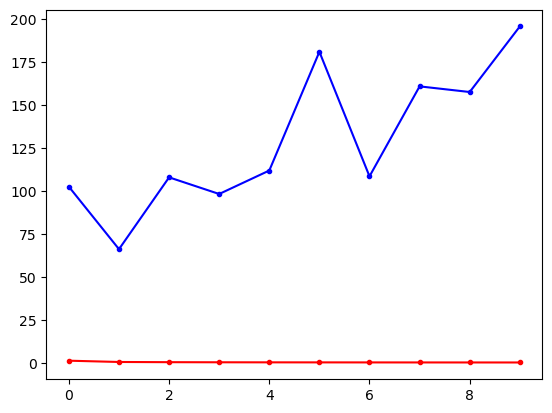

In [93]:
# Graficar la pérdida de la evolución del entrenamiento
plt.plot(historial.history["loss"], 'r', marker='.', label = 'Train Loss')
plt.plot(historial.history["val_loss"], 'b', marker='.', label = 'Validation Loss')
plt.show();

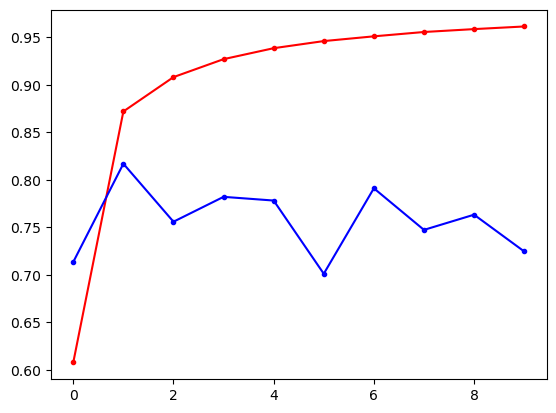

In [95]:
# Graficar la pérdida de la evolución del entrenamiento
plt.plot(historial.history["accuracy"], 'r', marker='.', label = 'Train Loss')
plt.plot(historial.history["val_accuracy"], 'b', marker='.', label = 'Validation Loss')
plt.show();